# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the car purchase dataset
dataset = pd.read_csv("car_purchase_data.csv")

# Display the first five records
print(dataset.head())

# Display the number of rows and columns
print(dataset.shape)

# Check for missing values
print(dataset.isnull().sum())


    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
(400, 5)
User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64


### Step 2: Split features and target

In [33]:
X = dataset[['Age', 'Salary']]
y = dataset['Purchased']

print(X.head())
print(y.head())

   Age  Salary
0   19   19000
1   35   20000
2   26   43000
3   27   57000
4   19   76000
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


### Step 3: Train/Test Split

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 320
Testing records: 80


### Step 4: Feature Scaling

In [35]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[:5])

[[ 1.92295008  2.14601566]
 [ 2.02016082  0.3787193 ]
 [-1.3822153  -0.4324987 ]
 [-1.18779381 -1.01194013]
 [ 1.92295008 -0.92502392]]


### Step 5: Train Logistic Regression Model

In [36]:
model = LogisticRegression(random_state=0, max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


### Step 6: Predict and Evaluate

In [37]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nFirst 5 Purchase Probabilities:")
print(model.predict_proba(X_test_scaled)[:5, 1])

Model Accuracy: 0.925
Accuracy Percentage: 92.5

Confusion Matrix:
[[57  1]
 [ 5 17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95        58
           1       0.94      0.77      0.85        22

    accuracy                           0.93        80
   macro avg       0.93      0.88      0.90        80
weighted avg       0.93      0.93      0.92        80


First 5 Purchase Probabilities:
[0.12601942 0.17694095 0.20772811 0.10091522 0.10703347]


### Step 7: Visualization of Decision Regions

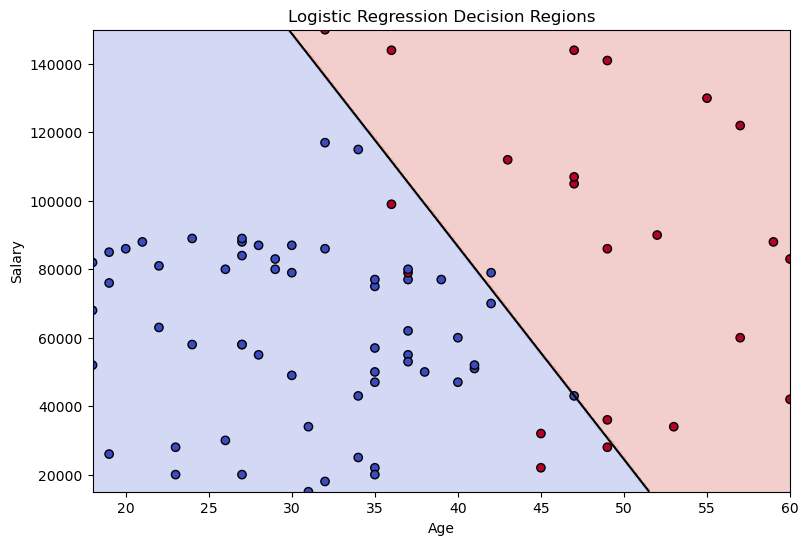

In [38]:
ages = np.linspace(X['Age'].min(), X['Age'].max(), 180)
salaries = np.linspace(X['Salary'].min(), X['Salary'].max(), 180)

xx, yy = np.meshgrid(ages, salaries)

grid = pd.DataFrame({
    'Age': xx.ravel(),
    'Salary': yy.ravel()
})

grid_scaled = scaler.transform(grid)

regions = model.predict(grid_scaled).reshape(xx.shape)
probabilities = model.predict_proba(grid_scaled)[:, 1].reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, regions, alpha=0.25, cmap='coolwarm')

plt.contour(xx, yy, probabilities,
            levels=[0.5], colors='black')

plt.scatter(X_test['Age'], X_test['Salary'],
            c=y_test, cmap='coolwarm',
            edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Logistic Regression Decision Regions')
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. Logistic regression outputs probabilities. Why can it still be used for classification?
Logistic regression predicts the probability of an outcome. We can convert that probability into a Yes or No prediction by using a threshold. For example, if the predicted probability is 0.5 or higher, the model predicts that the customer will purchase a car.

2. Based on your model, which customers are more likely to purchase a car?
Based on the model trained using this dataset, older customers and customers with higher salaries generally have a higher predicted probability of purchasing a car. Both age and salary have positive coefficients in the fitted model.

3. What factors might cause low accuracy in this task?
Low accuracy could result from limited customer information, overlapping purchasing patterns, or an unrepresentative training dataset. Age and salary alone may not explain every customer's purchasing decision.

4. Propose additional features or preprocessing steps that could improve accuracy.
Additional information such as employment status, current vehicle ownership, household income, and purchasing history could improve predictions. Testing different model settings, collecting more relevant data, and using cross-validation could also help evaluate and improve model performance.